# Figure 3: when and at which scales SWOT input is ahead of DUACS input

(a) Variance of SWOT minus DUACS on the swath by calendar month, July 2023 to September 2026, split at crossing
passes 11-37 h apart into a part seen on both passes (features DUACS misses, the internal tide among them) and a part
that is not (mostly SWOT noise); (b, c) the profile RMSE with DUACS input minus that with SWOT input, at S2 (centred
3-month windows) and at the moorings (calendar months); (d, e) the correlation of the signed mixed-layer density
gradient between mooring pairs with the observed one, by separation: SWOT minus DUACS input by month (d), and each
input and GLORYS12 over April-July (e). Asterisks mark where SWOT input is ahead at the 90% level.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
%matplotlib inline
from swot2argo import data, models, evaluate, gradients, plots
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
T = data.tests()

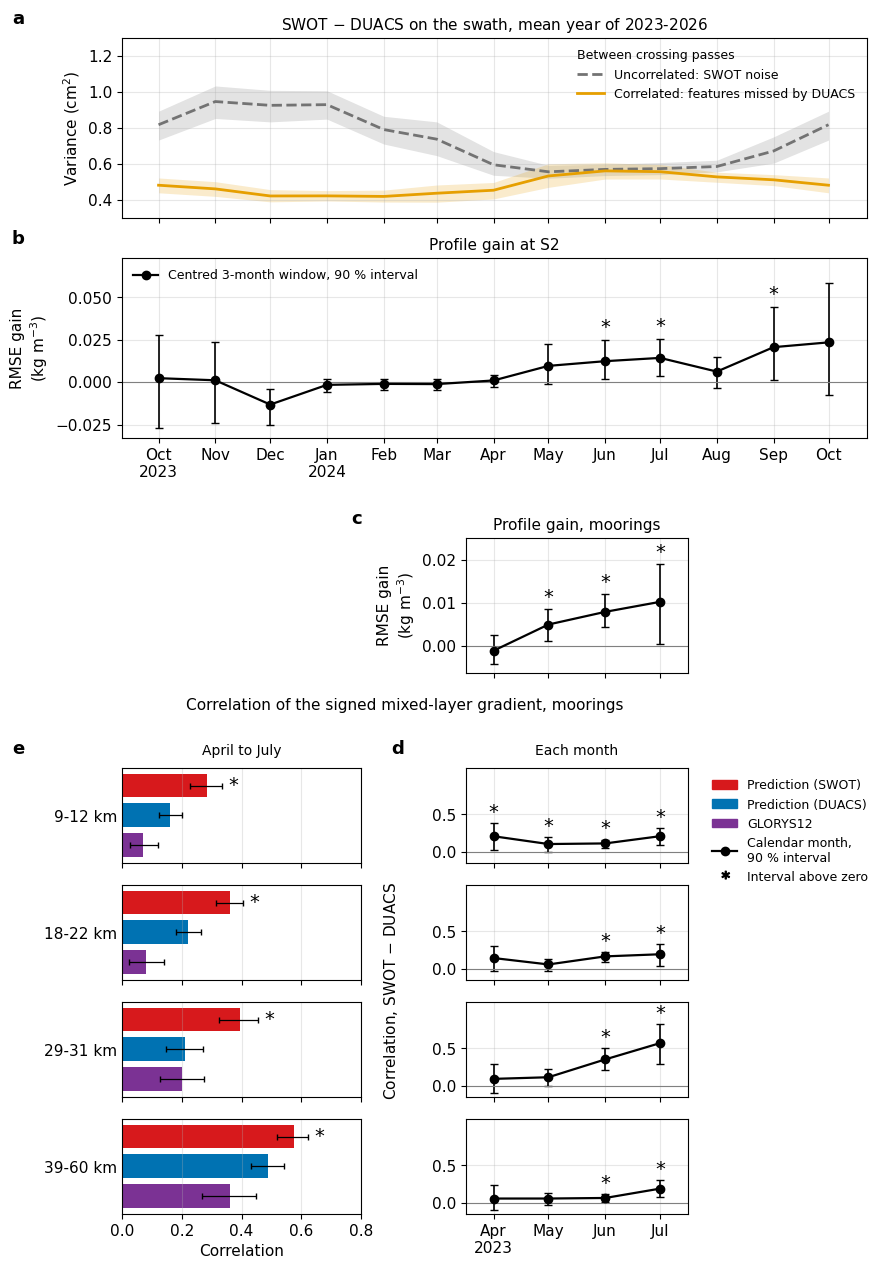

In [2]:
P, D = data.predictions(), data.gradients()
fig = plots.season_gain(P, T, D, data.swath_crossovers()); plt.show()

## The numbers the text quotes

The two SSHA inputs agree at a sample, less so in their difference between two moorings, which is what a horizontal
gradient sees; the correlation of the signed mixed-layer gradient with the observed one, by separation (SI Table S6);
and the profile gain at the moorings by month.

In [3]:
M = T["moorings"]
print("SWOT and DUACS SSHA at the moorings, correlation:", round(np.corrcoef(M.ssh_swot, M.ssh_duacs)[0, 1], 2))
for scale, (a, b, r) in gradients.pairs_by_scale(M).items():
    c = np.corrcoef(M.ssh_swot[a] - M.ssh_swot[b], M.ssh_duacs[a] - M.ssh_duacs[b])[0, 1]
    print(f"  their difference between moorings {scale}: {c:.2f}  ({len(a)} pairs)")

SWOT and DUACS SSHA at the moorings, correlation: 0.9
  their difference between moorings 5-15 km: 0.52  (698 pairs)
  their difference between moorings 15-25 km: 0.67  (677 pairs)
  their difference between moorings 25-35 km: 0.69  (546 pairs)
  their difference between moorings 35-60 km: 0.85  (1033 pairs)


In [4]:
ml = D[(D.platform == "moorings") & (D.layer == "ML interior")]
r = ml.pivot_table(index="scale", columns=["model", "field"], values="r", sort=False)
r[[("network", "SWOT"), ("network", "DUACS"), ("glorys12", "analysis")]].round(2)

model    network       glorys12
field       SWOT DUACS analysis
scale                          
5-15 km     0.28  0.16     0.07
15-25 km    0.36  0.22     0.08
25-35 km    0.39  0.21     0.20
35-60 km    0.57  0.49     0.36

In [5]:
es, ed = ((P["swot"]["moorings"] - M.dens) ** 2).mean(1), ((P["duacs"]["moorings"] - M.dens) ** 2).mean(1)
month = M.dates.month
print("moorings, RMSE with DUACS input minus with SWOT input (kg/m3):",
      {m: round(np.sqrt(ed[month == m].mean()) - np.sqrt(es[month == m].mean()), 3) for m in (4, 5, 6, 7)})

moorings, RMSE with DUACS input minus with SWOT input (kg/m3): {4: -0.001, 5: 0.005, 6: 0.008, 7: 0.01}
